In [1]:
import requests, time
import pandas as pd

rows = []
for year in range(2018, 2027):
    url = f"https://api.jolpi.ca/ergast/f1/{year}/drivers/max_verstappen/results.json?limit=100"
    data = requests.get(url, timeout=30).json()
    for race in data["MRData"]["RaceTable"]["Races"]:
        r = race["Results"][0]
        rows.append({
            "year": year,
            "round": int(race["round"]),
            "race": race["raceName"],
            "grid": int(r["grid"]),
            "finish": int(r["position"]),
            "status": r["status"],
        })
    time.sleep(1)  # be polite to the free API

df = pd.DataFrame(rows).sort_values(["year", "round"]).reset_index(drop=True)
df.to_csv("verstappen.csv", index=False)
df.tail(10)


,year,round,race,grid,finish,status
183,2026,11,Hungarian Grand Prix,4,2,Finished
184,2026,12,Dutch Grand Prix,7,22,Retired
185,2026,13,Italian Grand Prix,5,3,Finished
186,2026,14,Spanish Grand Prix,3,2,Finished
187,2026,15,Azerbaijan Grand Prix,8,2,Finished
188,2026,16,Bahrain Grand Prix in Malaysia,1,1,Finished
189,2026,17,Singapore Grand Prix,1,1,Finished
190,2026,18,United States Grand Prix,2,3,Finished
191,2026,19,Mexico City Grand Prix,5,1,Finished
192,2026,20,Brazilian Grand Prix,21,2,Finished


Matplotlib is building the font cache; this may take a moment.


(193, 6)
            grid    finish
grid    1.000000  0.145598
finish  0.145598  1.000000


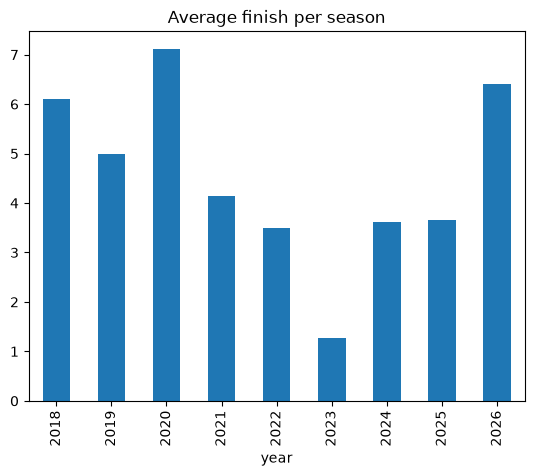

In [2]:
import matplotlib.pyplot as plt

print(df.shape)
print(df[["grid", "finish"]].corr())

df.groupby("year")["finish"].mean().plot(kind="bar", title="Average finish per season")
plt.show()

In [3]:
df["form_3"] = df["finish"].shift(1).rolling(3).mean()
df["form_5"] = df["finish"].shift(1).rolling(5).mean()
df["season_avg"] = (
    df.groupby("year")["finish"]
      .transform(lambda s: s.shift(1).expanding().mean())
)
data = df.dropna().copy()
data.tail()

,year,round,race,grid,finish,status,form_3,form_5,season_avg
188,2026,16,Bahrain Grand Prix in Malaysia,1,1,Finished,2.333333,6.2,8.000000
189,2026,17,Singapore Grand Prix,1,1,Finished,1.666667,6.0,7.562500
190,2026,18,United States Grand Prix,2,3,Finished,1.333333,1.8,7.176471
191,2026,19,Mexico City Grand Prix,5,1,Finished,1.666667,1.8,6.944444
192,2026,20,Brazilian Grand Prix,21,2,Finished,1.666667,1.6,6.631579


In [4]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

features = ["grid", "form_3", "form_5", "season_avg"]
train = data[data.year < 2025]
test = data[data.year == 2025]   # hold out the latest full season

# Baseline: "he'll finish about where he has recently"
print("Baseline MAE:", mean_absolute_error(test["finish"], test["form_5"]))

# Model 1: simple and hard to overfit
ridge = Ridge().fit(train[features], train["finish"])
print("Ridge MAE:   ", mean_absolute_error(test["finish"], ridge.predict(test[features])))

# Model 2: more flexible
gbr = GradientBoostingRegressor(random_state=0).fit(train[features], train["finish"])
print("GBR MAE:     ", mean_absolute_error(test["finish"], gbr.predict(test[features])))

Baseline MAE: 2.930434782608696
Ridge MAE:    2.7004179146971072
GBR MAE:      4.133597637319327


In [5]:
final = Ridge().fit(data[features], data["finish"])

grid_vegas = 1   # <- type his actual qualifying position here
this_year = df[df.year == 2026]

row = pd.DataFrame([{
    "grid": grid_vegas,
    "form_3": df["finish"].tail(3).mean(),
    "form_5": df["finish"].tail(5).mean(),
    "season_avg": this_year["finish"].mean(),
}])

pred = final.predict(row)[0]
print(f"Predicted finish: P{pred:.1f}")

Predicted finish: P3.2
